In [ ]:
import pandas as pd
df=pd.read_csv('/content/dataset.csv')
print(df.head())

   Marital status  Application mode  Application order  Course  \
0               1                 8                  5       2   
1               1                 6                  1      11   
2               1                 1                  5       5   
3               1                 8                  2      15   
4               2                12                  1       3   

   Daytime/evening attendance  Previous qualification  Nacionality  \
0                           1                       1            1   
1                           1                       1            1   
2                           1                       1            1   
3                           1                       1            1   
4                           0                       1            1   

   Mother's qualification  Father's qualification  Mother's occupation  ...  \
0                      13                      10                    6  ...   
1                       

In [ ]:
#PREPROCESSING OF DATA
df_sliced=df.iloc[:,[28,29,-1]].copy()
df_sliced.rename(columns={ 'Curricular units 2nd sem (approved)':'Cleared subject',
'Curricular units 2nd sem (grade)':'grade'},inplace=True)
#df_sliced['Target']={Dropout:0,Graduate:1}
df_sliced['Target']=df_sliced['Target'].map({'Dropout':0,'Graduate':1})
df_sliced = df_sliced.fillna(1)


print(df_sliced)

      Cleared subject      grade  Target
0                   0   0.000000     0.0
1                   6  13.666667     1.0
2                   0   0.000000     0.0
3                   5  12.400000     1.0
4                   6  13.000000     1.0
...               ...        ...     ...
4419                5  12.666667     1.0
4420                2  11.000000     0.0
4421                1  13.500000     0.0
4422                5  12.000000     1.0
4423                6  13.000000     1.0

[4424 rows x 3 columns]


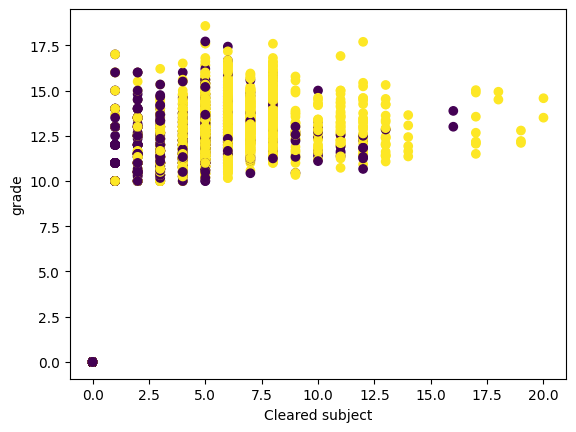

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df_sliced['Cleared subject'],df_sliced['grade'],c=df_sliced['Target']) # use [ ] to acces column
plt.xlabel('Cleared subject')
plt.ylabel('grade')
plt.show()


In [ ]:
x=df_sliced.iloc[:,0:2]
y=df_sliced.iloc[:,2:]

In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [ ]:
import numpy as np
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)



(3539, 2)
(885, 2)
(3539, 1)
(885, 1)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
#x_test=scaler.fit_transform(x_test)#data lekage
x_test=scaler.transform(x_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
clf=LogisticRegression()
clf.fit(x_train,y_train.values.ravel())

LogisticRegression()

In [ ]:
y_pred=clf.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.831638418079096

<Axes: >

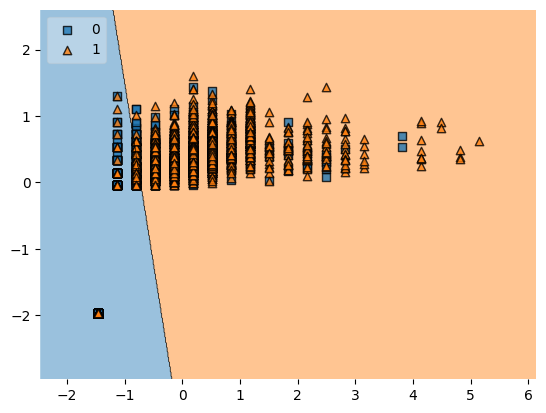

In [137]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(x_train, y_train.values.astype(int).ravel(), clf=clf, legend=2)
